In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv("../data/breast_cancer_wdbc.csv")

# Display first 5 records
df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,radius2,texture2,perimeter2,area2,smoothness2,compactness2,concavity2,concave_points2,symmetry2,fractal_dimension2,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [3]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset Information:")
df.info()

Dataset Shape: (569, 31)

Column Names:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3', 'diagnosis']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6 

In [4]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Series([], dtype: int64)

Total Missing Values: 0


In [5]:
# Count duplicate records
duplicates = df.duplicated().sum()

print("Number of Duplicate Records:", duplicates)

Number of Duplicate Records: 0


In [6]:
# Statistical summary of numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [7]:
# Count records in each diagnosis category
diagnosis_counts = df["diagnosis"].value_counts().sort_index()

# Display counts
print("Diagnosis Distribution:")
print("Benign (0):", diagnosis_counts[0])
print("Malignant (1):", diagnosis_counts[1])

print("\nTotal Records:", diagnosis_counts.sum())

Diagnosis Distribution:
Benign (0): 357
Malignant (1): 212

Total Records: 569


In [8]:
# Calculate diagnosis percentages
diagnosis_percentages = df["diagnosis"].value_counts(normalize=True) * 100

print("Class Distribution Percentage:")
print(diagnosis_percentages.sort_index().round(2))

Class Distribution Percentage:
diagnosis
0    62.74
1    37.26
Name: proportion, dtype: float64


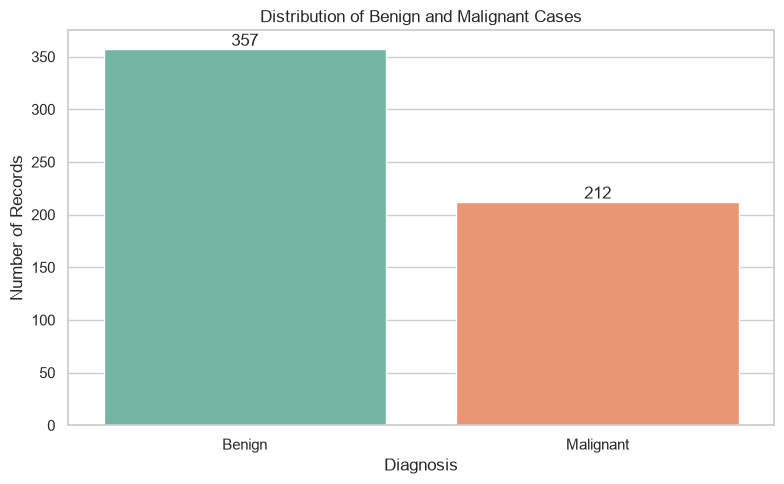

In [9]:
# Create labels for diagnosis categories
class_labels = ["Benign", "Malignant"]

# Create bar chart
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Benign and Malignant Cases")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.xticks([0, 1], class_labels)

# Display count above each bar
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

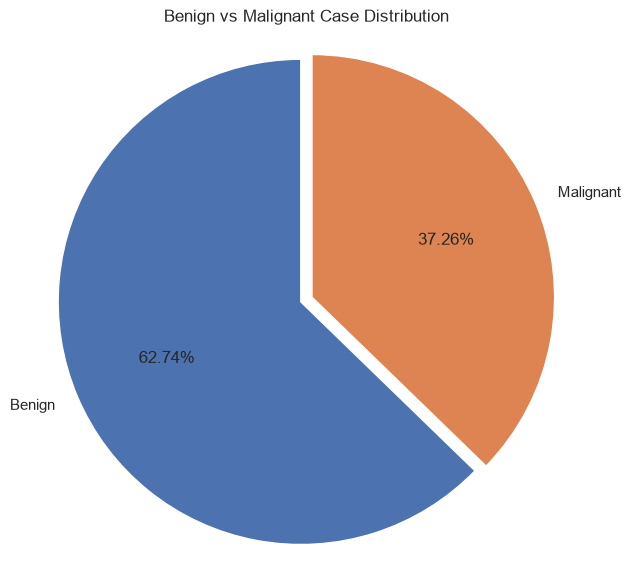

In [10]:
# Prepare pie chart data
labels = ["Benign", "Malignant"]
sizes = [diagnosis_counts[0], diagnosis_counts[1]]

plt.figure(figsize=(7, 7))

plt.pie(
    sizes,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90,
    explode=(0, 0.05)
)

plt.title("Benign vs Malignant Case Distribution")
plt.axis("equal")

plt.show()

### Class Distribution Analysis – Observation

The dataset contains 569 records, consisting of 357 Benign cases (62.74%) and 212 Malignant cases (37.26%).

Benign cases represent the majority class, while Malignant cases represent the minority class. The dataset has a moderate class imbalance.

Since identifying malignant cases is important in breast cancer detection, model evaluation should give particular attention to malignant-class recall and false negatives rather than relying only on overall accuracy.

In [11]:
# Select the 10 mean features
mean_features = [
    "radius1",
    "texture1",
    "perimeter1",
    "area1",
    "smoothness1",
    "compactness1",
    "concavity1",
    "concave_points1",
    "symmetry1",
    "fractal_dimension1"
]

print("Mean Features:")
print(mean_features)

Mean Features:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1']


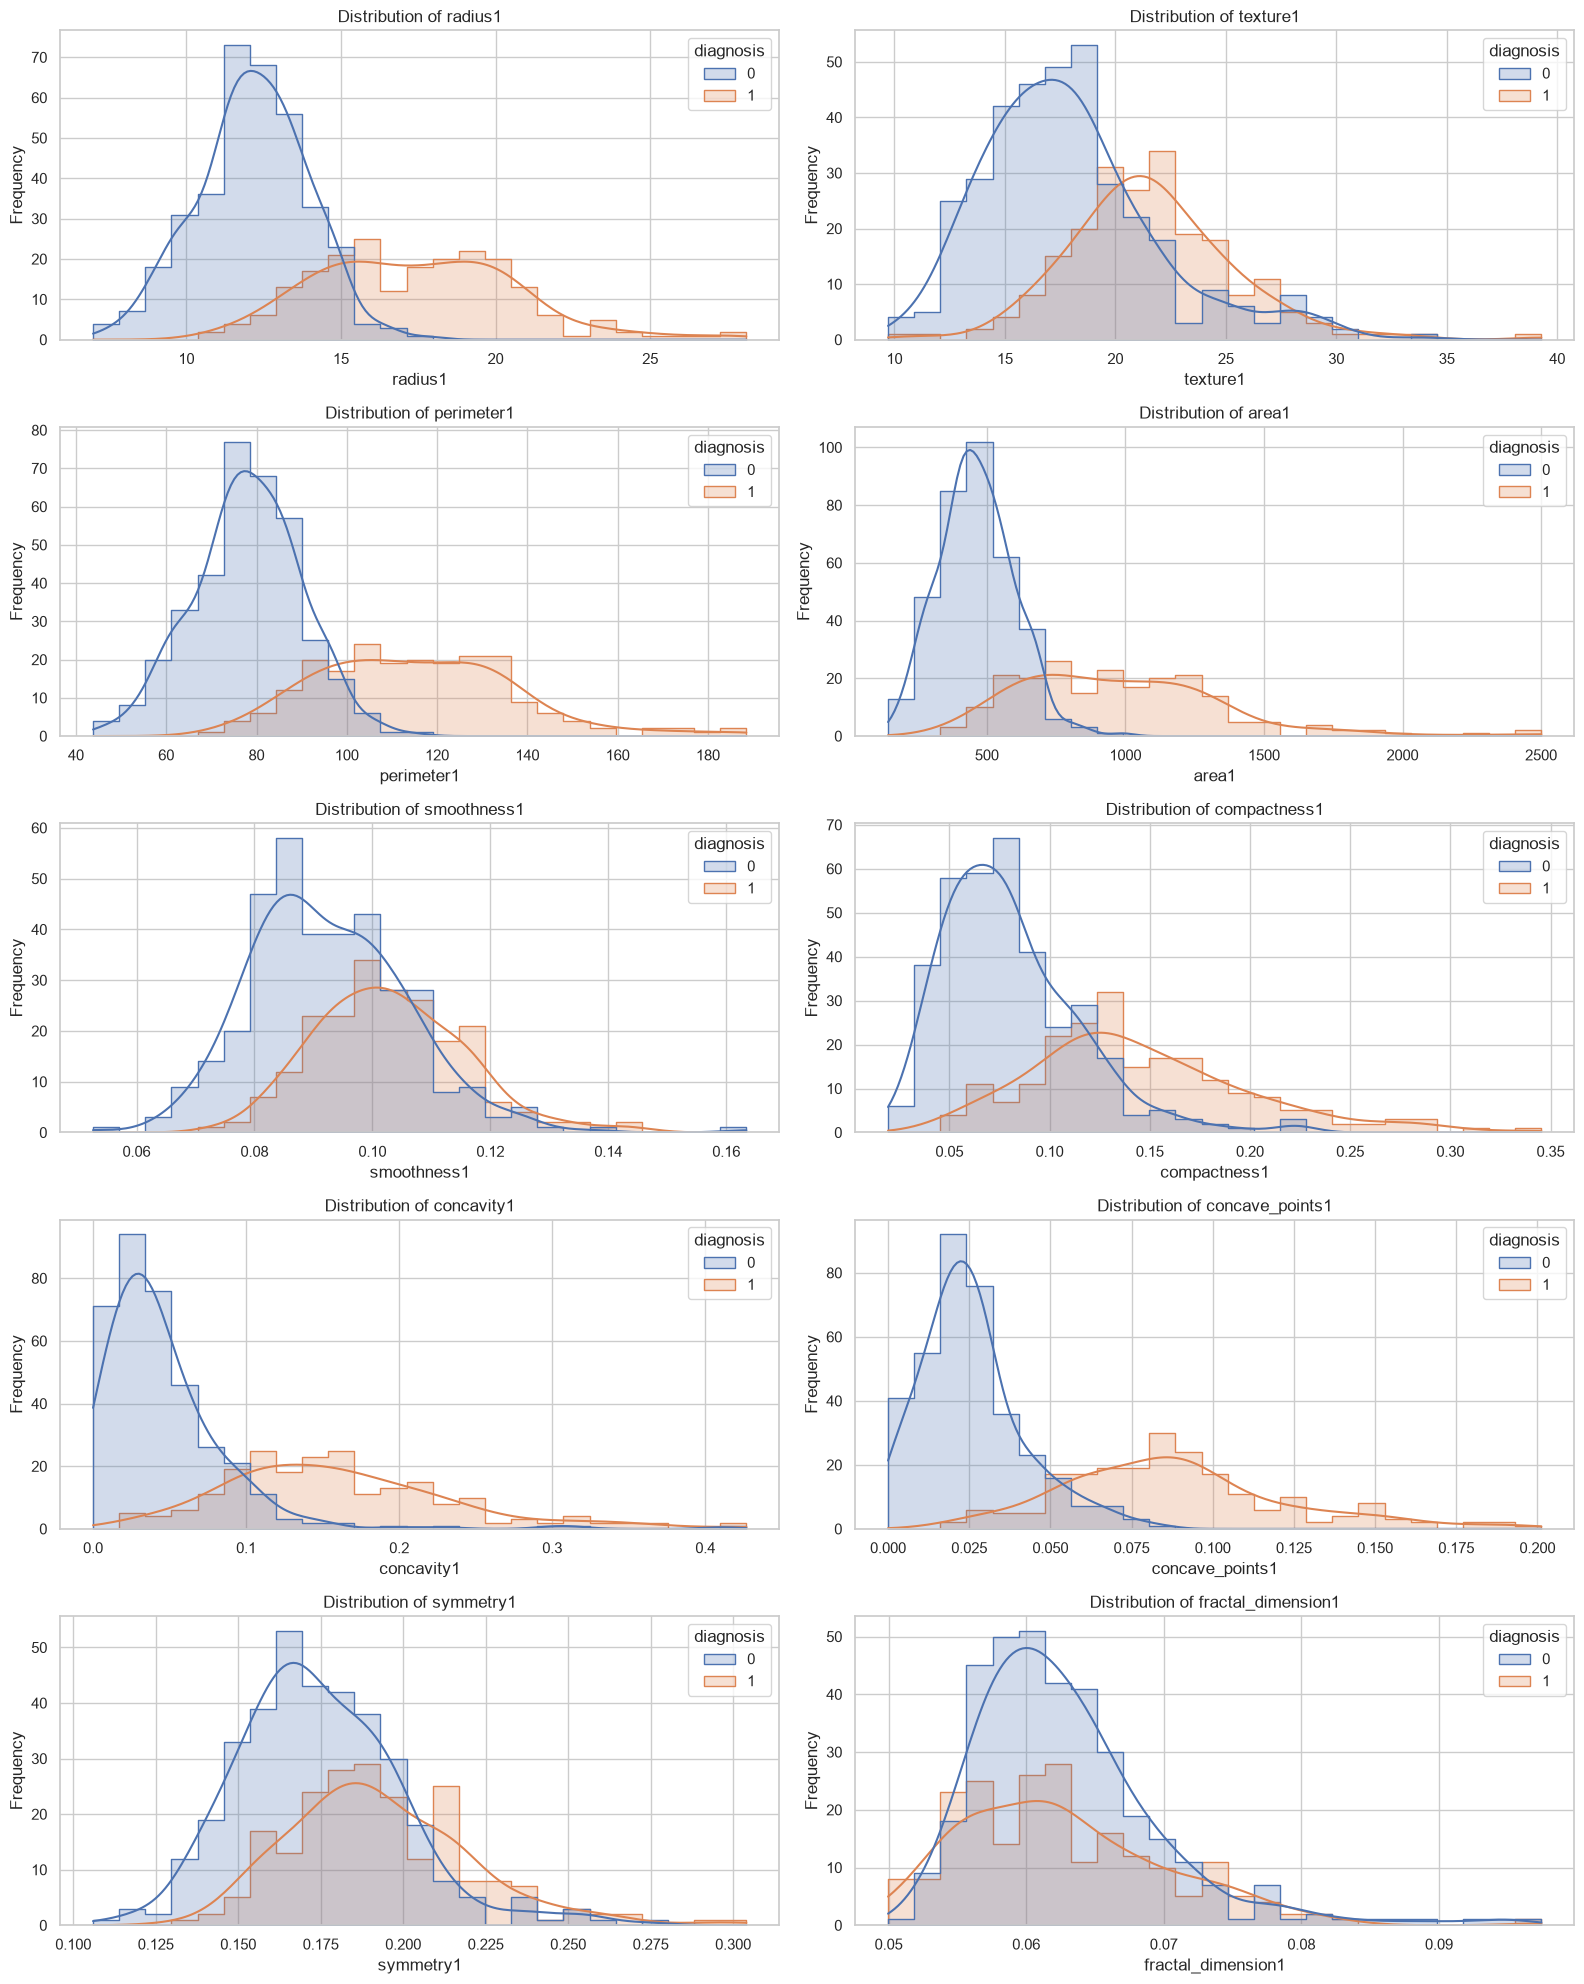

In [12]:
# Plot distributions of mean features by diagnosis
plt.figure(figsize=(16, 20))

for i, feature in enumerate(mean_features, 1):
    plt.subplot(5, 2, i)

    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        kde=True,
        bins=25,
        element="step"
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

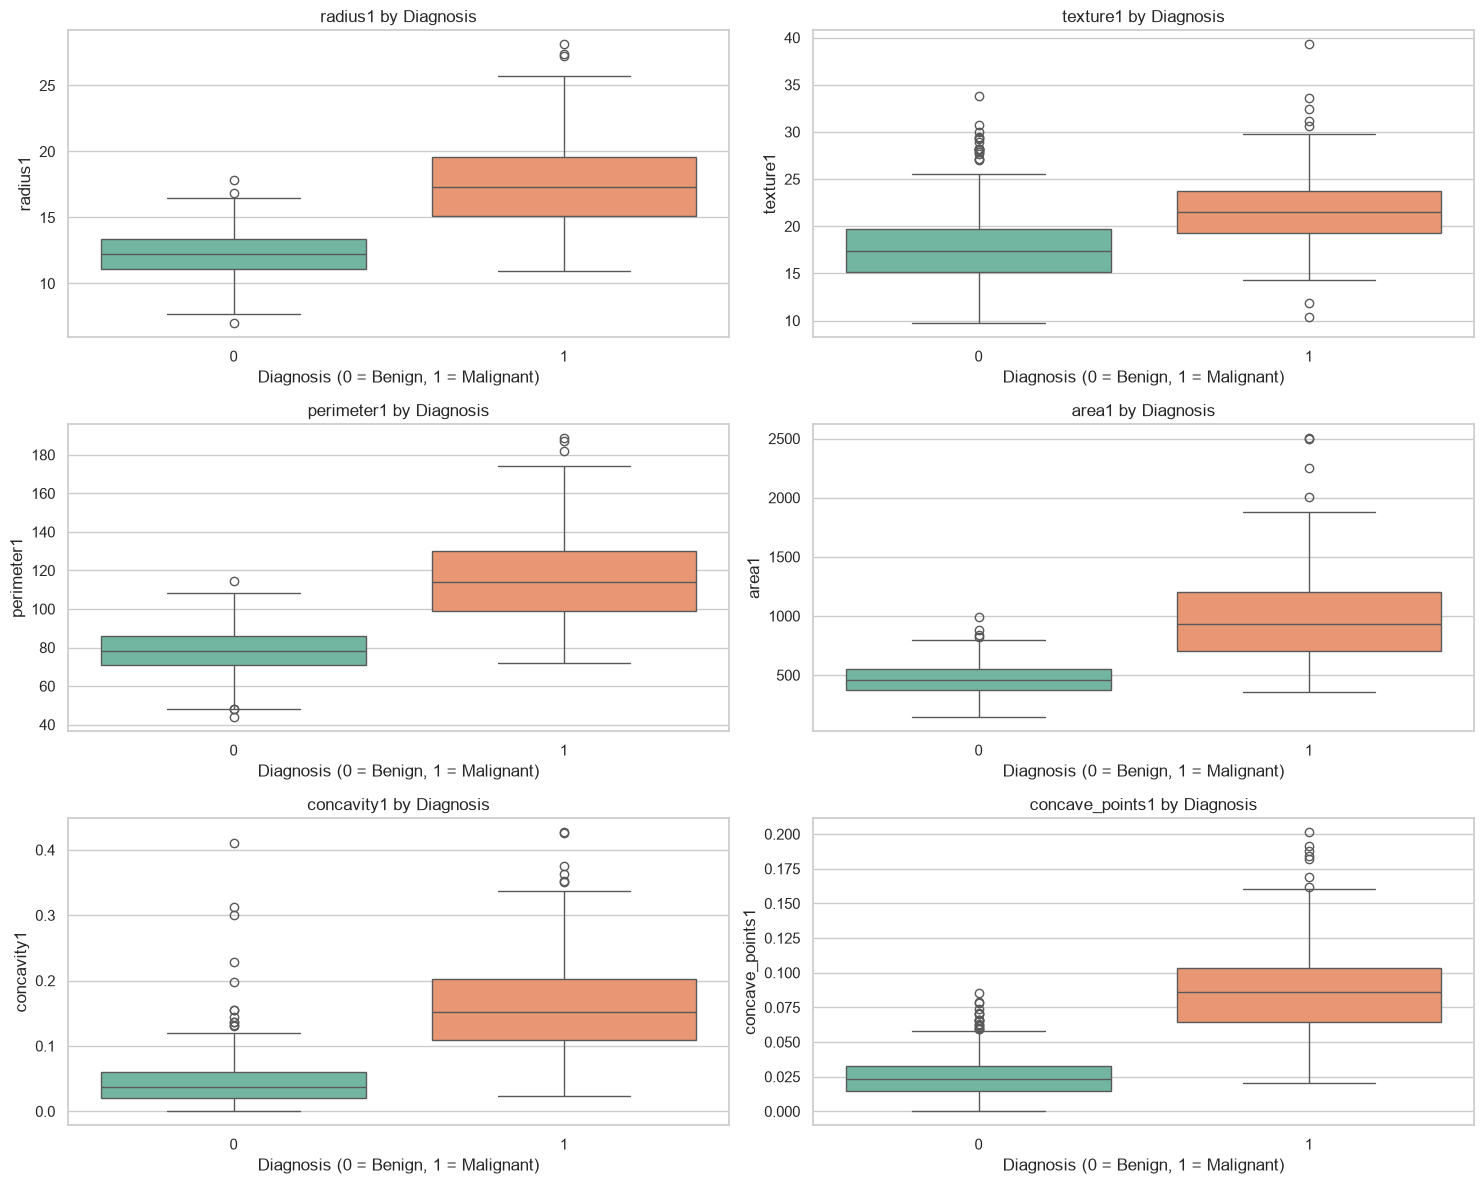

In [13]:
# Select important features for comparison
important_features = [
    "radius1",
    "texture1",
    "perimeter1",
    "area1",
    "concavity1",
    "concave_points1"
]

plt.figure(figsize=(15, 12))

for i, feature in enumerate(important_features, 1):
    plt.subplot(3, 2, i)

    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        hue="diagnosis",
        palette="Set2",
        legend=False
    )

    plt.title(f"{feature} by Diagnosis")
    plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

In [14]:
# Calculate mean feature values for each diagnosis
feature_comparison = df.groupby("diagnosis")[mean_features].mean().T

feature_comparison.columns = ["Benign", "Malignant"]

display(feature_comparison.round(3))

,Benign,Malignant
radius1,12.147,17.463
texture1,17.915,21.605
perimeter1,78.075,115.365
area1,462.790,978.376
smoothness1,0.092,0.103
compactness1,0.080,0.145
concavity1,0.046,0.161
concave_points1,0.026,0.088
symmetry1,0.174,0.193
fractal_dimension1,0.063,0.063


### Feature Distribution Analysis – Observation

The feature distribution analysis compares the numerical characteristics of Benign and Malignant cases.

The histograms and boxplots help identify differences in feature values, data spread, and potential outliers between the two diagnosis groups.

Features such as radius, perimeter, area, concavity, and concave points are useful to investigate because their distributions may differ between Benign and Malignant cases.

These observations help identify potentially informative features for the machine learning models. However, feature importance must be evaluated using appropriate statistical or model-based techniques rather than visual inspection alone.

In [15]:
# Select numerical features
numerical_features = df.drop(columns=["diagnosis"])

# Calculate correlation matrix
correlation_matrix = numerical_features.corr()

# Display correlation matrix
display(correlation_matrix.round(2))

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,radius2,texture2,perimeter2,area2,smoothness2,compactness2,concavity2,concave_points2,symmetry2,fractal_dimension2,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
radius1,1.00,0.32,1.00,0.99,0.17,0.51,0.68,0.82,0.15,-0.31,0.68,-0.10,0.67,0.74,-0.22,0.21,0.19,0.38,-0.10,-0.04,0.97,0.30,0.97,0.94,0.12,0.41,0.53,0.74,0.16,0.01
texture1,0.32,1.00,0.33,0.32,-0.02,0.24,0.30,0.29,0.07,-0.08,0.28,0.39,0.28,0.26,0.01,0.19,0.14,0.16,0.01,0.05,0.35,0.91,0.36,0.34,0.08,0.28,0.30,0.30,0.11,0.12
perimeter1,1.00,0.33,1.00,0.99,0.21,0.56,0.72,0.85,0.18,-0.26,0.69,-0.09,0.69,0.74,-0.20,0.25,0.23,0.41,-0.08,-0.01,0.97,0.30,0.97,0.94,0.15,0.46,0.56,0.77,0.19,0.05
area1,0.99,0.32,0.99,1.00,0.18,0.50,0.69,0.82,0.15,-0.28,0.73,-0.07,0.73,0.80,-0.17,0.21,0.21,0.37,-0.07,-0.02,0.96,0.29,0.96,0.96,0.12,0.39,0.51,0.72,0.14,0.00
smoothness1,0.17,-0.02,0.21,0.18,1.00,0.66,0.52,0.55,0.56,0.58,0.30,0.07,0.30,0.25,0.33,0.32,0.25,0.38,0.20,0.28,0.21,0.04,0.24,0.21,0.81,0.47,0.43,0.50,0.39,0.50
compactness1,0.51,0.24,0.56,0.50,0.66,1.00,0.88,0.83,0.60,0.57,0.50,0.05,0.55,0.46,0.14,0.74,0.57,0.64,0.23,0.51,0.54,0.25,0.59,0.51,0.57,0.87,0.82,0.82,0.51,0.69
concavity1,0.68,0.30,0.72,0.69,0.52,0.88,1.00,0.92,0.50,0.34,0.63,0.08,0.66,0.62,0.10,0.67,0.69,0.68,0.18,0.45,0.69,0.30,0.73,0.68,0.45,0.75,0.88,0.86,0.41,0.51
concave_points1,0.82,0.29,0.85,0.82,0.55,0.83,0.92,1.00,0.46,0.17,0.70,0.02,0.71,0.69,0.03,0.49,0.44,0.62,0.10,0.26,0.83,0.29,0.86,0.81,0.45,0.67,0.75,0.91,0.38,0.37
symmetry1,0.15,0.07,0.18,0.15,0.56,0.60,0.50,0.46,1.00,0.48,0.30,0.13,0.31,0.22,0.19,0.42,0.34,0.39,0.45,0.33,0.19,0.09,0.22,0.18,0.43,0.47,0.43,0.43,0.70,0.44
fractal_dimension1,-0.31,-0.08,-0.26,-0.28,0.58,0.57,0.34,0.17,0.48,1.00,0.00,0.16,0.04,-0.09,0.40,0.56,0.45,0.34,0.35,0.69,-0.25,-0.05,-0.21,-0.23,0.50,0.46,0.35,0.18,0.33,0.77


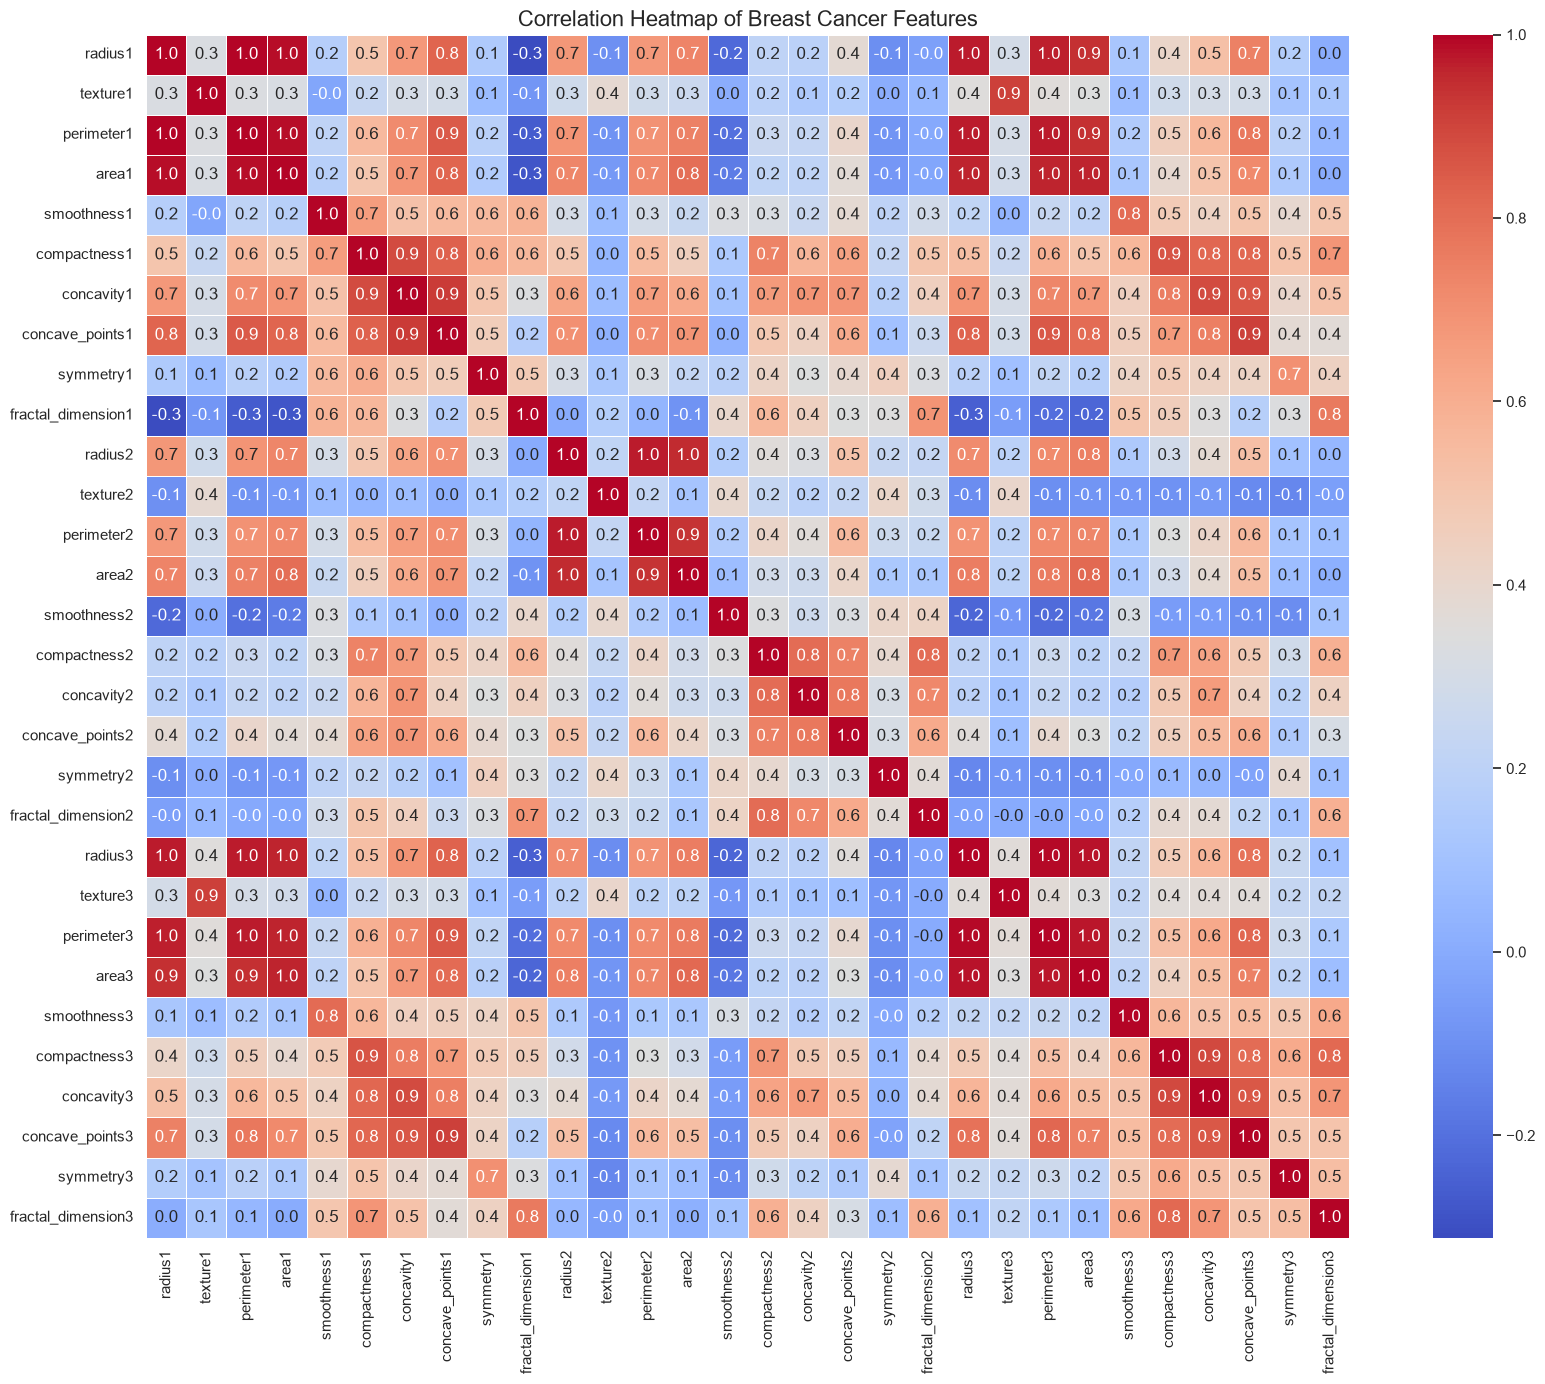

In [16]:
# Create correlation heatmap
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".1f",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Breast Cancer Features", fontsize=16)
plt.tight_layout()
plt.show()

In [17]:
# Get upper triangle of correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.85
high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_correlations = high_correlations[
    high_correlations["Correlation"].abs() > 0.85
]

high_correlations = high_correlations.sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

display(high_correlations)

,Feature 1,Feature 2,Correlation
2,radius1,perimeter1,0.997855
622,radius3,perimeter3,0.993708
3,radius1,area1,0.987357
63,perimeter1,area1,0.986507
623,radius3,area3,0.984015
683,perimeter3,area3,0.977578
312,radius2,perimeter2,0.972794
82,perimeter1,perimeter3,0.970387
20,radius1,radius3,0.969539
80,perimeter1,radius3,0.969476


In [18]:
# Calculate correlation between features and diagnosis
diagnosis_correlation = df.corr(numeric_only=True)["diagnosis"]

# Remove diagnosis's correlation with itself
diagnosis_correlation = diagnosis_correlation.drop("diagnosis")

# Sort by absolute correlation
diagnosis_correlation = diagnosis_correlation.reindex(
    diagnosis_correlation.abs().sort_values(ascending=False).index
)

display(diagnosis_correlation.to_frame("Correlation with Diagnosis"))

,Correlation with Diagnosis
concave_points3,0.793566
perimeter3,0.782914
concave_points1,0.776614
radius3,0.776454
perimeter1,0.742636
area3,0.733825
radius1,0.730029
area1,0.708984
concavity1,0.696360
concavity3,0.659610


In [19]:
# Select numerical features
numerical_features = df.drop(columns=["diagnosis"])

# Calculate outliers using IQR
outlier_summary = []

for feature in numerical_features.columns:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        by="Outlier Count",
        ascending=False
    )
)

,Feature,Lower Bound,Upper Bound,Outlier Count
13,area2,-23.160000,86.200000,65
10,radius2,-0.137350,0.848650,38
12,perimeter2,-1.020500,5.983500,38
23,area3,-337.750000,1937.050000,35
14,smoothness2,0.000703,0.012612,30
19,fractal_dimension2,-0.001217,0.008023,28
15,compactness2,-0.015975,0.061505,28
18,symmetry2,0.002680,0.035960,27
3,area1,-123.300000,1326.300000,25
29,fractal_dimension3,0.040530,0.123010,24


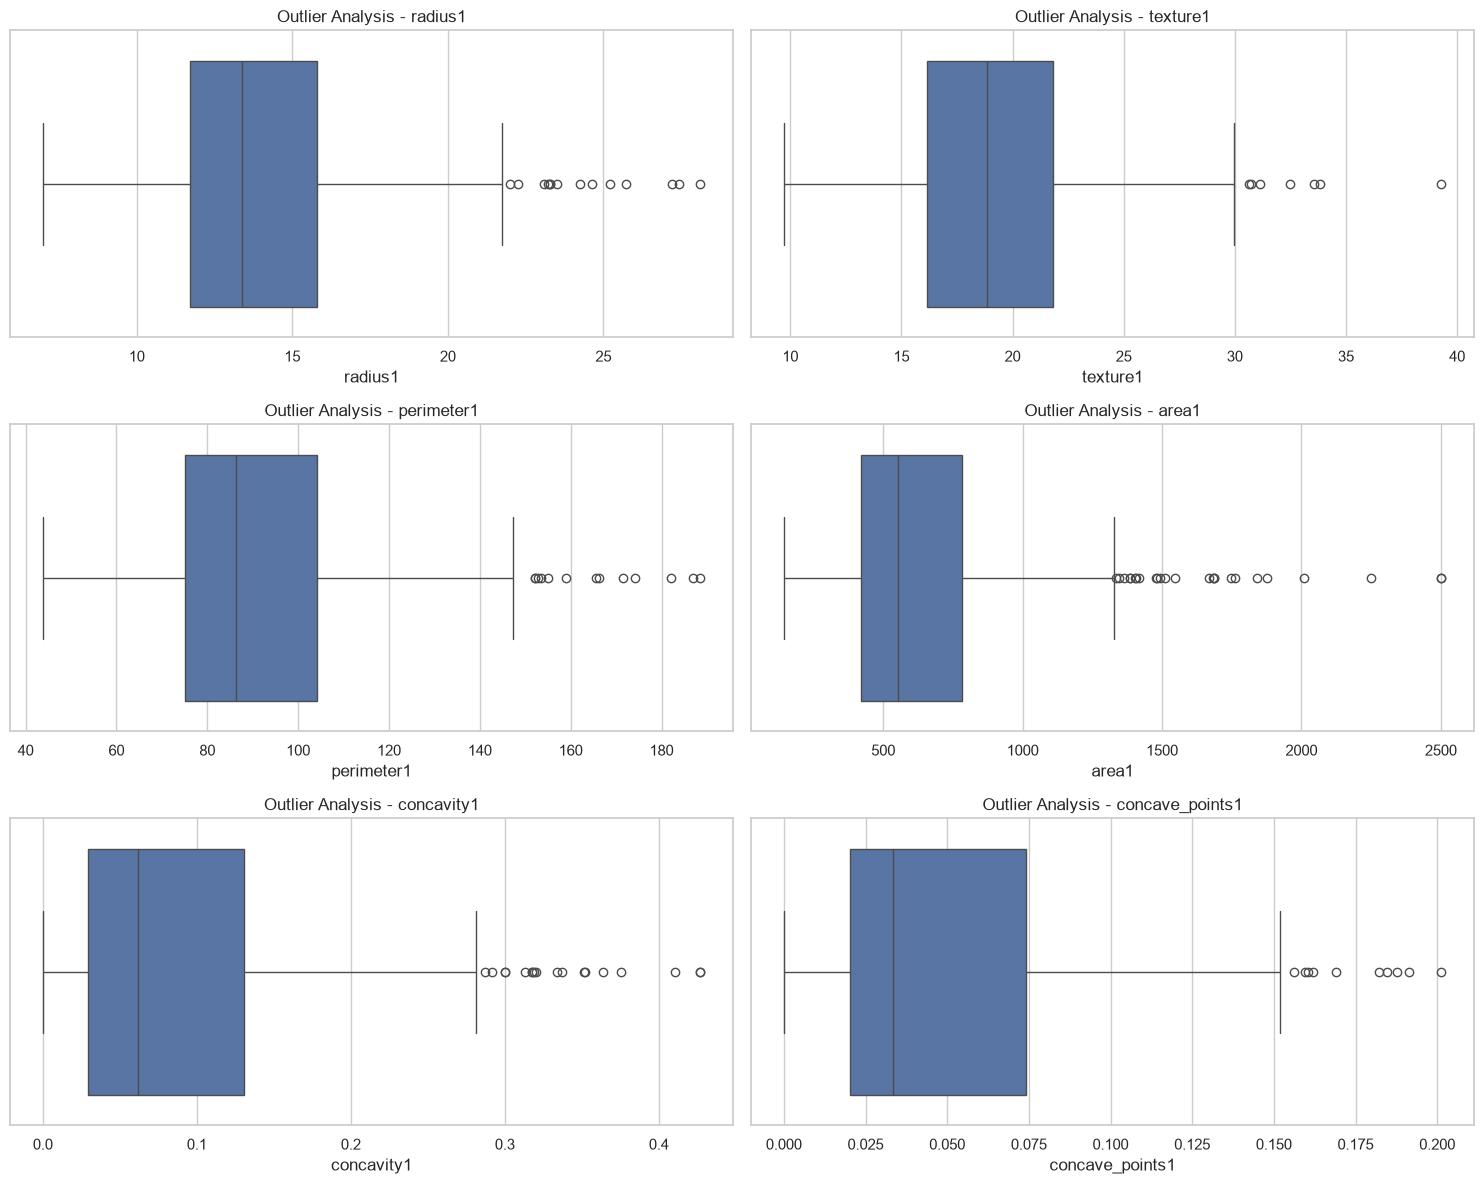

In [20]:
# Select important features
outlier_features = [
    "radius1",
    "texture1",
    "perimeter1",
    "area1",
    "concavity1",
    "concave_points1"
]

plt.figure(figsize=(15, 12))

for i, feature in enumerate(outlier_features, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(
        data=df,
        x=feature
    )

    plt.title(f"Outlier Analysis - {feature}")
    plt.xlabel(feature)

plt.tight_layout()
plt.show()

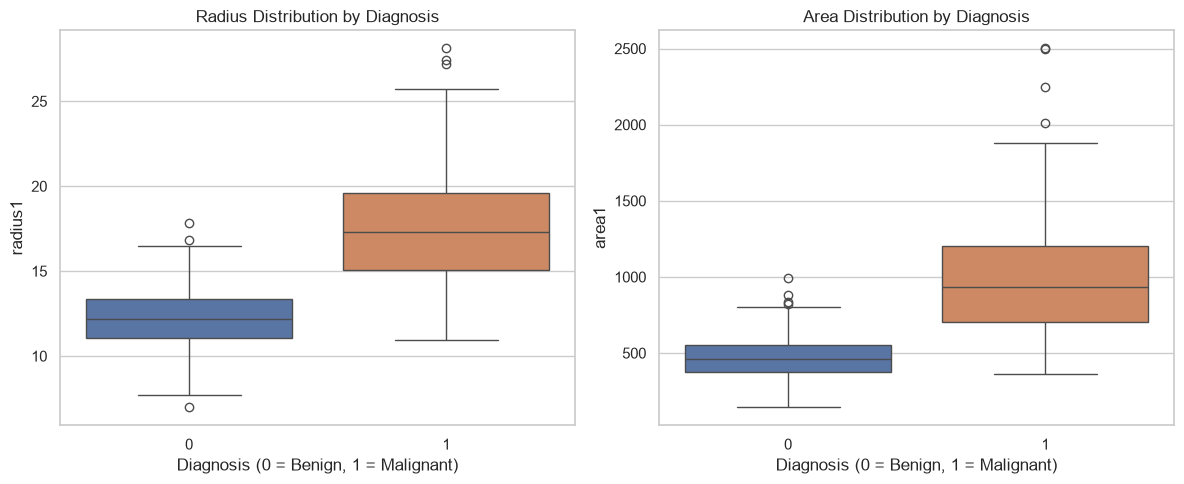

In [21]:
# Compare radius and area across diagnosis groups
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.boxplot(
    data=df,
    x="diagnosis",
    y="radius1",
    hue="diagnosis",
    legend=False
)

plt.title("Radius Distribution by Diagnosis")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")

plt.subplot(1, 2, 2)

sns.boxplot(
    data=df,
    x="diagnosis",
    y="area1",
    hue="diagnosis",
    legend=False
)

plt.title("Area Distribution by Diagnosis")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")

plt.tight_layout()
plt.show()

### Outlier Analysis – Observation

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical features of the Breast Cancer Wisconsin Diagnostic dataset.

Boxplots were generated to examine the distribution and spread of selected features, including radius, texture, perimeter, area, concavity, and concave points.

Some observations may fall outside the IQR boundaries. These values are considered potential outliers and require further investigation.

Since unusually high or low measurements may represent genuine tumour characteristics, they should not be removed automatically. The original measurements should be preserved unless there is evidence of data errors.

In [22]:
import os

# Create folder to store EDA visualizations
os.makedirs("reports/eda", exist_ok=True)

print("EDA reports folder created successfully!")

EDA reports folder created successfully!


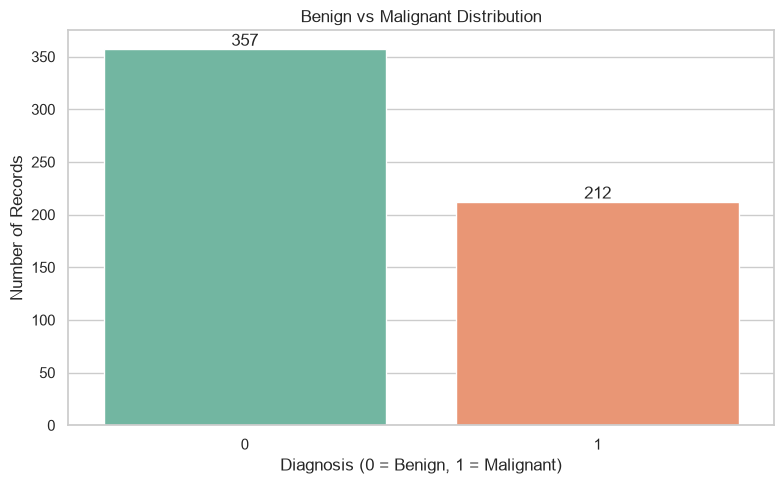

In [23]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.title("Benign vs Malignant Distribution")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Records")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig("reports/eda/class_distribution.png", dpi=300)
plt.show()

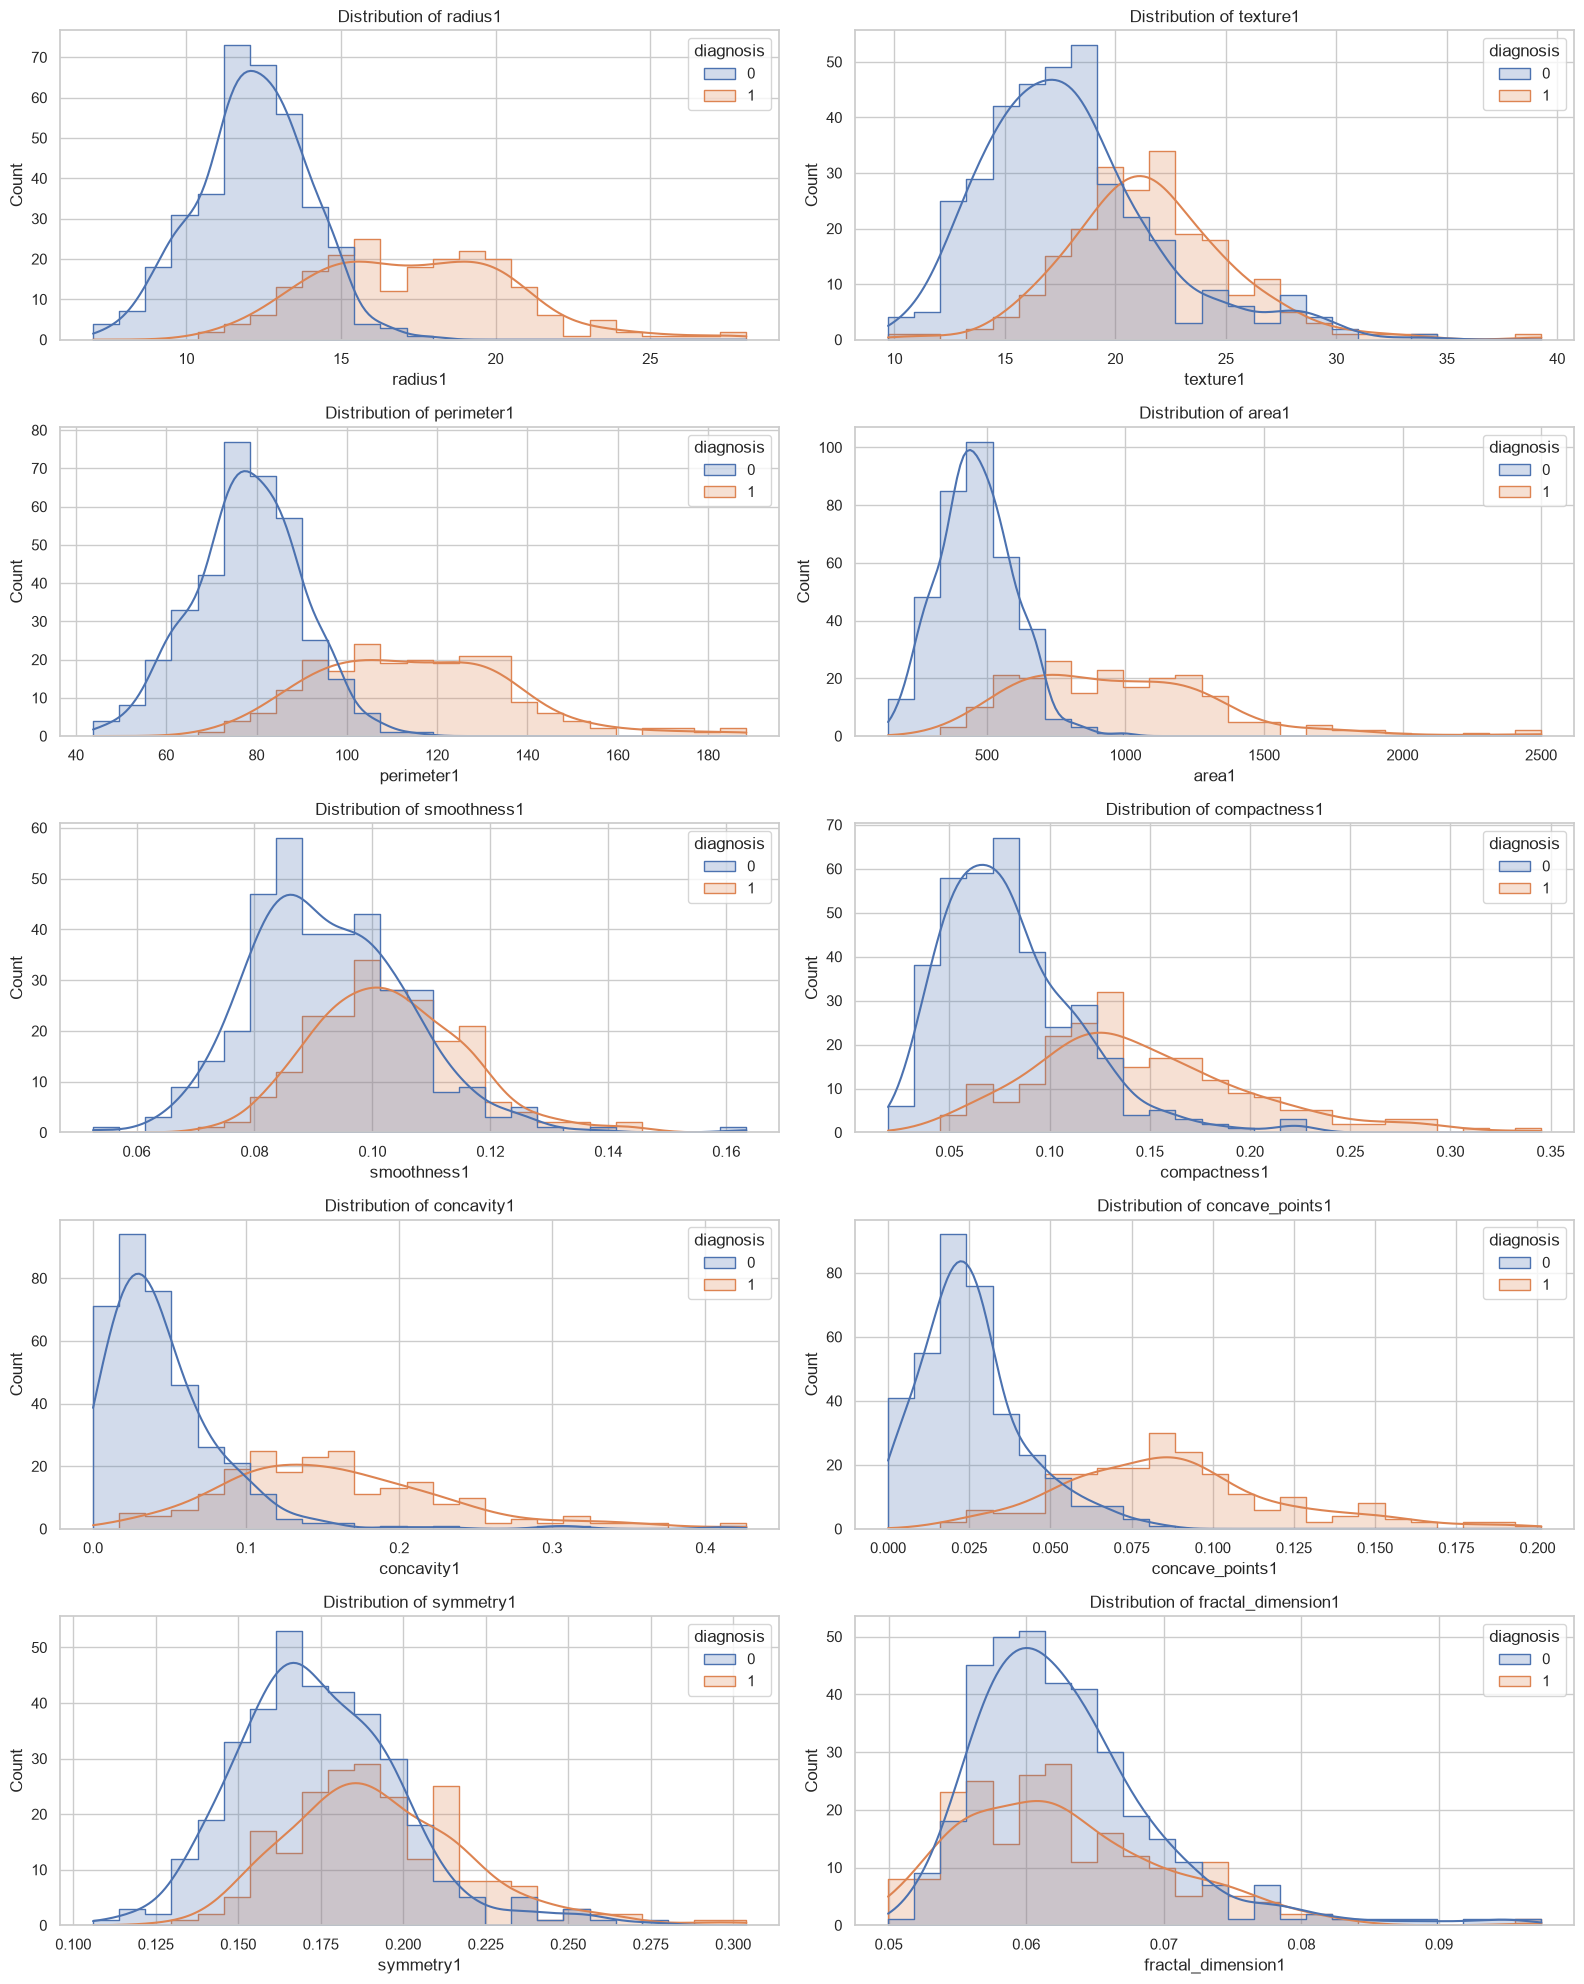

In [24]:
mean_features = [
    "radius1", "texture1", "perimeter1", "area1",
    "smoothness1", "compactness1", "concavity1",
    "concave_points1", "symmetry1", "fractal_dimension1"
]

plt.figure(figsize=(16, 20))

for i, feature in enumerate(mean_features, 1):
    plt.subplot(5, 2, i)

    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        kde=True,
        bins=25,
        element="step"
    )

    plt.title(f"Distribution of {feature}")

plt.tight_layout()
plt.savefig("reports/eda/feature_distributions.png", dpi=300)
plt.show()

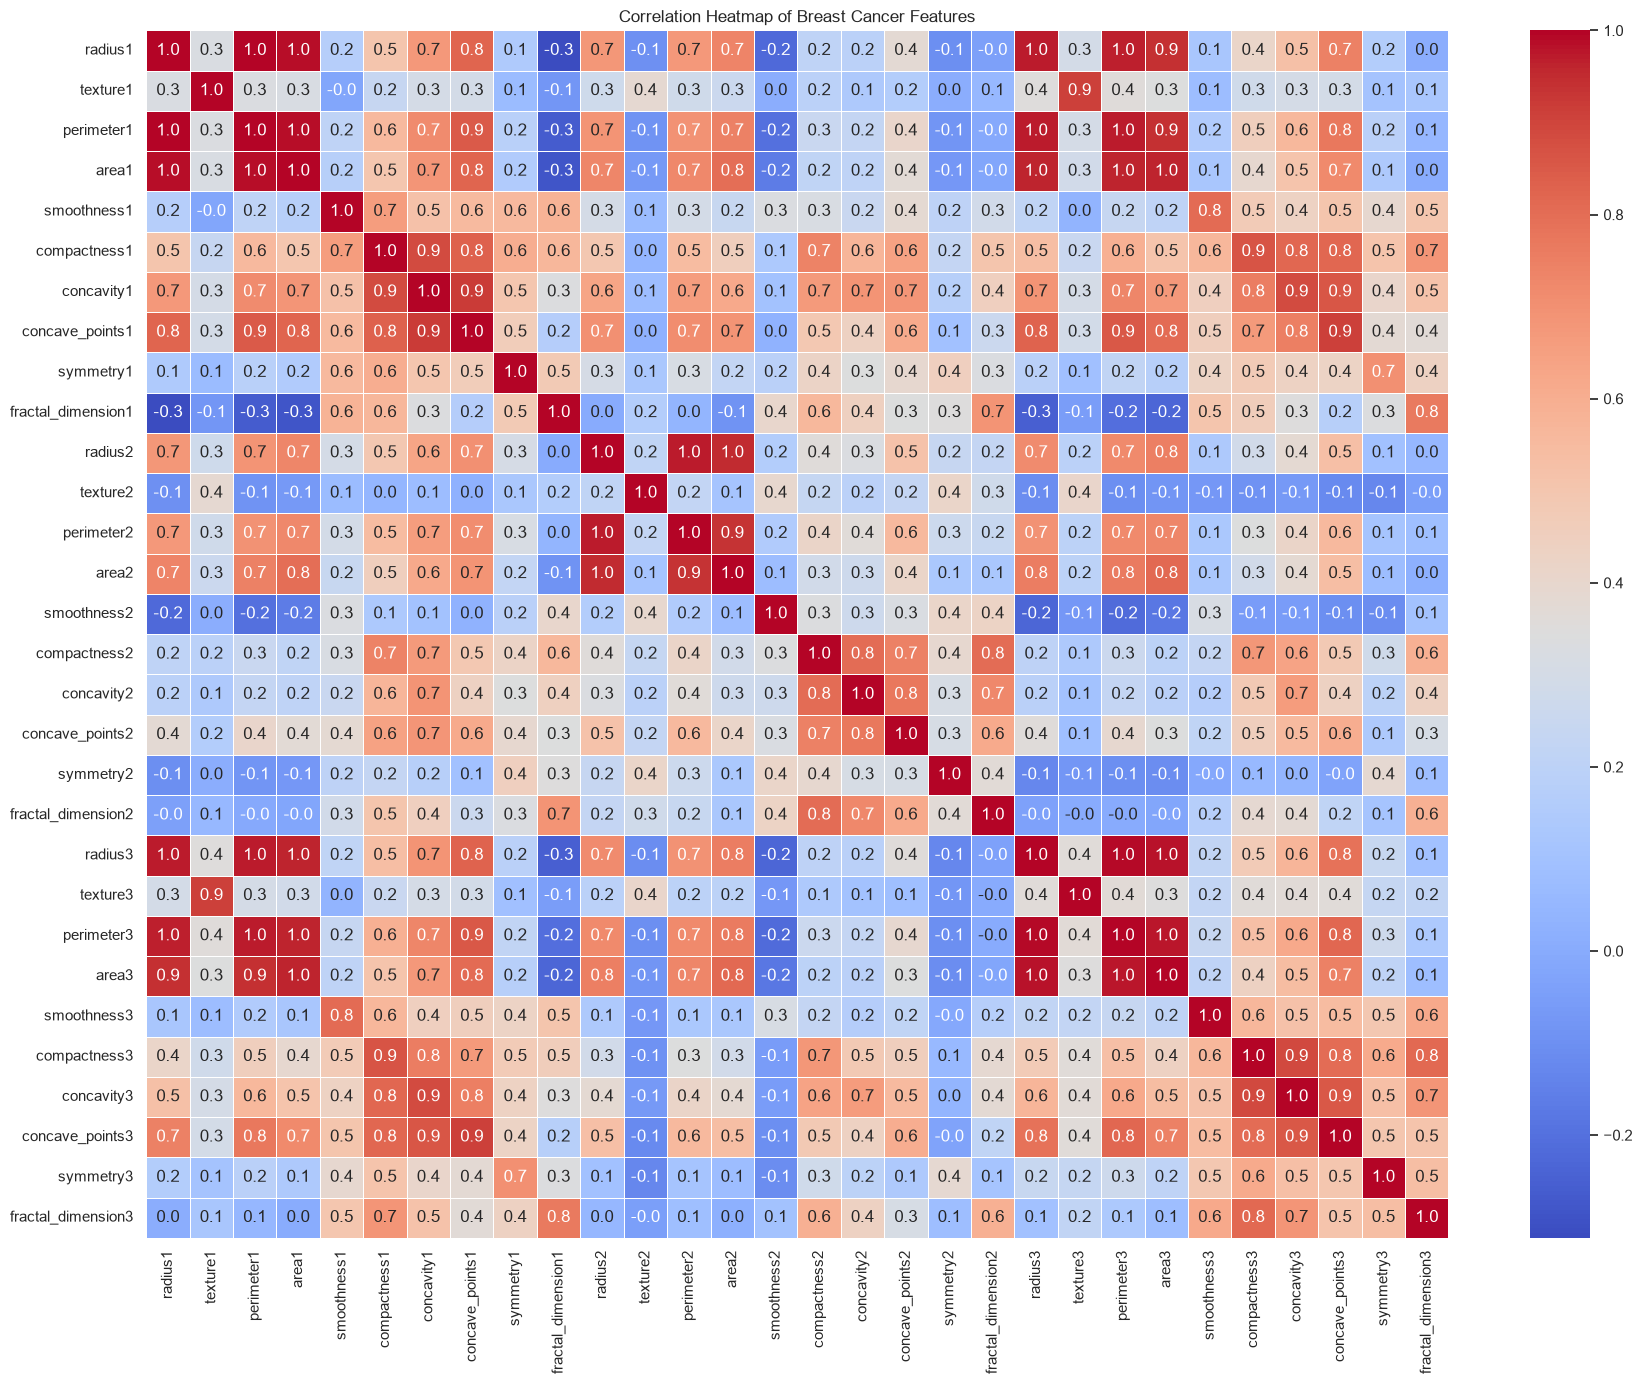

In [25]:
correlation_matrix = df.drop(columns=["diagnosis"]).corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()

plt.savefig("reports/eda/correlation_heatmap.png", dpi=300)
plt.show()

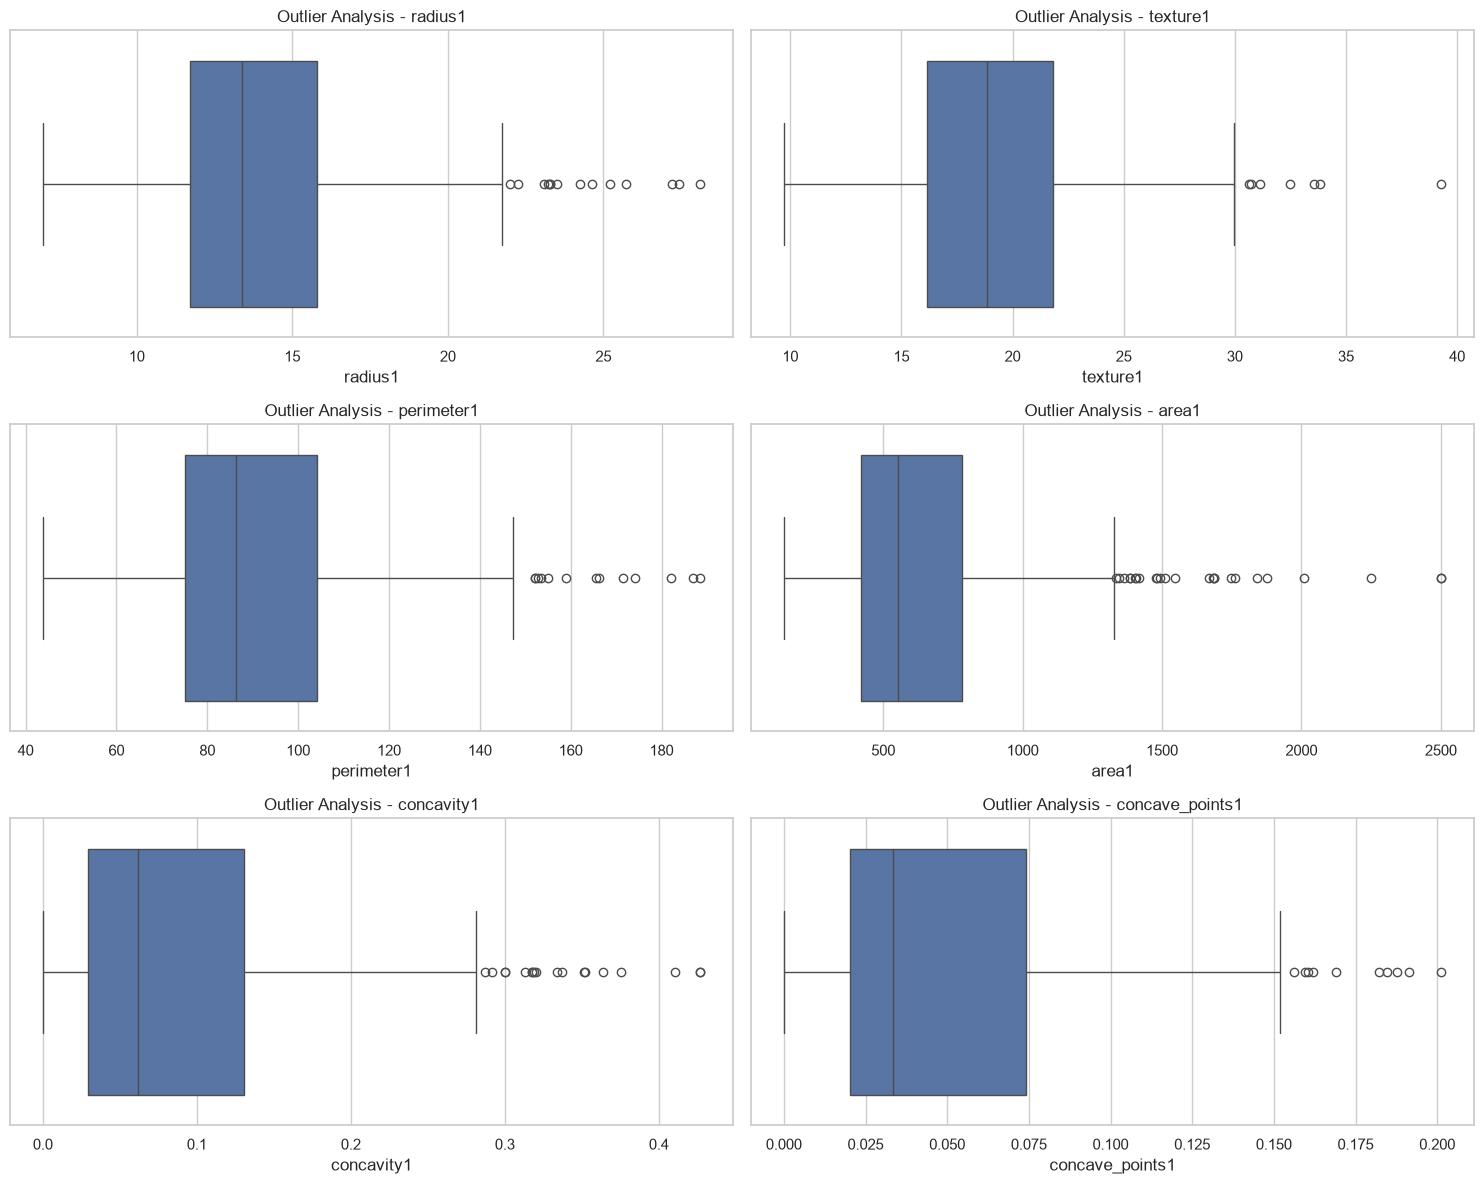

In [26]:
outlier_features = [
    "radius1",
    "texture1",
    "perimeter1",
    "area1",
    "concavity1",
    "concave_points1"
]

plt.figure(figsize=(15, 12))

for i, feature in enumerate(outlier_features, 1):
    plt.subplot(3, 2, i)

    sns.boxplot(data=df, x=feature)

    plt.title(f"Outlier Analysis - {feature}")

plt.tight_layout()

plt.savefig("reports/eda/outlier_analysis.png", dpi=300)
plt.show()

Exploratory Data Analysis – Key Findings

1. Dataset Overview
The Breast Cancer Wisconsin Diagnostic dataset contains 569 records, 30 numerical input features, and one target column named diagnosis.

2. Class Distribution
The dataset contains 357 Benign cases (62.74%) and 212 Malignant cases (37.26%). Benign cases form the majority class.

3. Feature Distribution
Feature distribution plots and boxplots were used to compare numerical measurements between Benign and Malignant cases. Features such as radius, perimeter, area, concavity, and concave points were examined.

4. Correlation Analysis
The correlation heatmap was used to identify relationships among numerical features. Some related measurements may contain overlapping information.

5. Outlier Analysis
The Interquartile Range (IQR) method was used to identify potential outliers. These values require investigation and should not automatically be removed because they may represent genuine measurements.

6. Conclusion
EDA provided an understanding of the dataset structure, class distribution, feature characteristics, correlations, and potential outliers. These findings will guide the preprocessing and machine learning stages.

In [28]:
import shutil
import os

# Create ZIP file containing EDA visualizations
zip_path = shutil.make_archive(
    "EDA_Visualizations",
    "zip",
    "reports/eda"
)

print("ZIP file created successfully!")
print("File location:", os.path.abspath(zip_path))

ZIP file created successfully!
File location: c:\Users\U Krushna moorthy\OneDrive\Desktop\Breast_Cancer_Detection\notebooks\EDA_Visualizations.zip
